In [1]:
from sklearn.datasets import fetch_olivetti_faces

data=fetch_olivetti_faces()

X = data.data
y = data.target

print(X.shape)
print(y.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
(400, 4096)
(400,)


In [2]:
print(data)

{'data': array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
        0.1570248 ],
       [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
        0.15289256],
       [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
        0.15289256],
       ...,
       [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
        0.19008264],
       [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
        0.60330576],
       [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
        0.38429752]], dtype=float32), 'images': array([[[0.30991736, 0.3677686 , 0.41735536, ..., 0.37190083,
         0.3305785 , 0.30578512],
        [0.3429752 , 0.40495867, 0.43801653, ..., 0.37190083,
         0.338843  , 0.3140496 ],
        [0.3429752 , 0.41735536, 0.45041323, ..., 0.38016528,
         0.338843  , 0.29752067],
        ...,
        [0.21487603, 0.20661157, 0.2231405 , ..., 0.15289256,
         0.16528925, 0.17

In [3]:
import numpy as np
#Roll Number- M26CSA005
roll_num_char=26005
seed=roll_num_char 
rng=np.random.default_rng(seed)

print(seed)

26005


In [4]:
Xtrain_ids=[]
Xval_ids=[]
Xtest_ids=[]

for face in range(40):
    ids=np.where(y == face)[0]
    rng.shuffle(ids)

    Xtrain_ids.extend(ids[:6])
    Xval_ids.extend(ids[6:8])
    Xtest_ids.extend(ids[8:])

Xtrain_ids=np.array(Xtrain_ids)
Xval_ids=np.array(Xval_ids)
Xtest_ids=np.array(Xtest_ids)


np.savez(
    "olivetti_split.npz",
    Xtrain_ids=Xtrain_ids,
    Xval_ids=Xval_ids,
    Xtest_ids=Xtest_ids
)


X_train, y_train = X[Xtrain_ids], y[Xtrain_ids]
X_val, y_val = X[Xval_ids], y[Xval_ids]
X_test, y_test = X[Xtest_ids], y[Xtest_ids]


In [5]:
import matplotlib.pyplot as plt

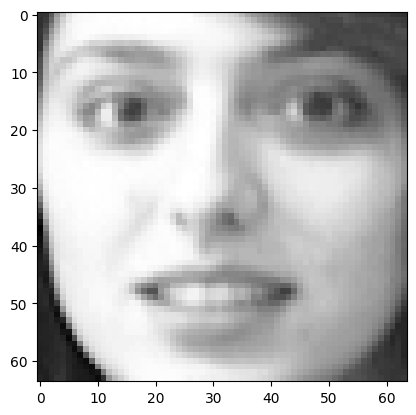

In [6]:
plt.imshow(X_test[14].reshape(64, 64), cmap="gray")
plt.show()

In [7]:
Xtest_mask=X_test.copy()
Xtest_mask=Xtest_mask.reshape(-1,64,64)
Xtest_mask[:,24:40,24:40]=0
Xtest_mask=Xtest_mask.reshape(-1,4096)

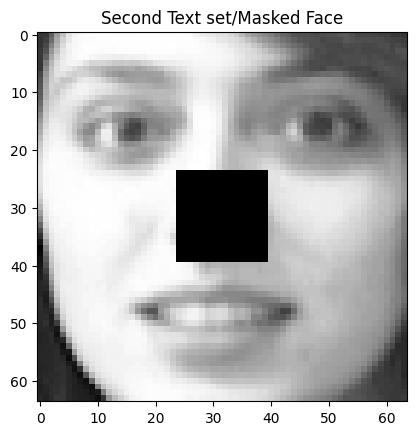

In [8]:
plt.imshow(Xtest_mask[14].reshape(64, 64), cmap="gray")
plt.title("Second Text set/Masked Face")
plt.show()

# Q1. Decision tree baseline and bagging from scratch

In [9]:
#(a) First establish a single tree baseline. Train DecisionTreeClassifier models with max depth∈ {2, 4, 8, 16, None}
#and min samples leaf∈ {1, 2, 4}. Select one setting using validation accuracy only and freeze it. Report train,
#validation and test accuracy, number of leaves, mean samples per leaf and the fraction of leaves containing only
#one training example. Explain what changes as depth increases.

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [11]:
depths=[2,8,4,16,None]
leaf_sizes=[1,2,4]

frozen_results=[]

for depth in depths:
    for leaf_size in leaf_sizes:

        tree=DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=seed
        )


        tree.fit(X_train,y_train)

        train_pred=tree.predict(X_train)
        val_pred=tree.predict(X_val)

        train_acc=accuracy_score(y_train,train_pred)
        val_acc=accuracy_score(y_val,val_pred)

        frozen_results.append({
            "depth":depth,
            "leaf_size":leaf_size,
            "train_acc":train_acc,
            "val_acc":val_acc,
            "tree":tree
        })

        if len(frozen_results) == 1:
            print(f"{'Depth':<8}{'Leaf Size':<12}{'Train Accuracy':<18}{'Validation Accuracy'}")
        print(
            f"{str(depth):<8}"
            f"{leaf_size:<12}"
            f"{train_acc:<18.4f}"
            f"{val_acc:.4f}"
        )

Depth   Leaf Size   Train Accuracy    Validation Accuracy
2       1           0.0750            0.0625
2       2           0.0750            0.0625
2       4           0.0750            0.0625
8       1           0.2250            0.1875
8       2           0.2250            0.1875
8       4           0.2250            0.1875
4       1           0.1250            0.1125
4       2           0.1250            0.1125
4       4           0.1250            0.1125
16      1           0.4250            0.2750
16      2           0.4250            0.2750
16      4           0.4250            0.2750
None    1           1.0000            0.6125
None    2           0.9875            0.5875
None    4           0.9792            0.5750


In [12]:
best = max(frozen_results, key=lambda item: item["val_acc"])

tree = best["tree"]
print("Depth:", best["depth"])
print("Minimum leaf size:", best["leaf_size"])
print("Training accuracy:", round(best["train_acc"], 4))
print("Validation accuracy:", round(best["val_acc"], 4))


Depth: None
Minimum leaf size: 1
Training accuracy: 1.0
Validation accuracy: 0.6125


In [13]:
test_pred = tree.predict(X_test)
test_acc = accuracy_score(y_test, test_pred)

leaf_ids = tree.apply(X_train)

leaf_numbers, leaf_counts = np.unique(
    leaf_ids, return_counts=True
)

num_leaves = len(leaf_counts)
mean_samples = np.mean(leaf_counts)
single_sample_fraction = np.mean(leaf_counts == 1)

print("Q1 (a) results/solution")
print("\nDepth:", best["depth"])
print("Minimum leaf size:", best["leaf_size"])
print("Training accuracy:", round(best["train_acc"], 4))
print("Validation accuracy:", round(best["val_acc"], 4))
print("Test accuracy:", round(test_acc, 4))
print("Number of leaves:", num_leaves)
print("Mean samples per leaf:", round(mean_samples, 2))
print(
    "Fraction of leaves with one training image:",
    round(single_sample_fraction, 4)
)


Q1 (a) results/solution

Depth: None
Minimum leaf size: 1
Training accuracy: 1.0
Validation accuracy: 0.6125
Test accuracy: 0.4625
Number of leaves: 46
Mean samples per leaf: 5.22
Fraction of leaves with one training image: 0.1304


# (b) Implement bagging yourself using bootstrap samples of the original training set size and the frozen tree setting from part (a). Use B ∈ {1, 5, 10, 25, 50, 100, 200}. For every B, report train, validation and test accuracy and the average number of distinct examples in one bootstrap sample. Compare the last quantity with its theoretical expectation.

In [14]:
tree_counts = [1, 5, 10, 25, 50, 100, 200]
bagg_rng=np.random.default_rng(seed)

trees=[]
samples=[]
bagg_results=[]

for i in range(200):
    ids=bagg_rng.integers(0,len(X_train),size=len(X_train))
    new_tree=DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=1,
        random_state=seed+1
    )